# Challenge 1: datos y análisis exploratorio

Tu primera responsabilidad es preparar una fuente de datos confiable para el proyecto de clasificación de vinos.

**Entrada:** `data/raw/wine.csv`  
**Salidas:** `data/processed/train.csv`, `data/processed/test.csv` y `artifacts/data_contract.json`

> El conjunto de test se crea aquí, pero no debe explorarse ni utilizarse después del split.

## Objetivos

- cargar y validar datos externos;
- identificar problemas básicos de calidad;
- crear un split reproducible y estratificado;
- realizar EDA únicamente sobre entrenamiento;
- guardar datos y metadatos para la siguiente etapa.

In [1]:
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split

np.random.seed(42)
plt.rcParams["figure.figsize"] = (7, 4)

In [2]:
from pathlib import Path

PROJECT_DIR = Path.cwd()
RAW_DATA_DIR = PROJECT_DIR / "data" / "raw"
PROCESSED_DATA_DIR = PROJECT_DIR / "data" / "processed"
ARTIFACTS_DIR = PROJECT_DIR / "artifacts"
REPORTS_DIR = PROJECT_DIR / "reports"

for directory in (PROCESSED_DATA_DIR, ARTIFACTS_DIR, REPORTS_DIR):
    directory.mkdir(parents=True, exist_ok=True)

RANDOM_STATE = 42

## 1. Carga y profiling

In [3]:
DATA_PATH = RAW_DATA_DIR / "wine.csv"

df = pd.read_csv(DATA_PATH)

In [4]:
print("Dimensiones:", df.shape)
print("\nTipos de datos:\n", df.dtypes)
print("\nValores nulos por columna:\n", df.isna().sum())
print("\nFilas duplicadas:", df.duplicated().sum())
print("\nDistribucion de target:\n", df["target"].value_counts().sort_index())

Dimensiones: (178, 14)

Tipos de datos:
 alcohol                         float64
malic_acid                      float64
ash                             float64
alcalinity_of_ash               float64
magnesium                       float64
total_phenols                   float64
flavanoids                      float64
nonflavanoid_phenols            float64
proanthocyanins                 float64
color_intensity                 float64
hue                             float64
od280/od315_of_diluted_wines    float64
proline                         float64
target                            int64
dtype: object

Valores nulos por columna:
 alcohol                         0
malic_acid                      0
ash                             0
alcalinity_of_ash               0
magnesium                       0
total_phenols                   0
flavanoids                      0
nonflavanoid_phenols            0
proanthocyanins                 0
color_intensity                 0
hue             

**Conclusión de calidad:**

El archivo tiene 178 filas, 13 variables predictoras numéricas y `target`. No se encontraron valores nulos ni filas duplicadas. Las clases tienen 59, 71 y 48 observaciones, por lo que se conservan todas las filas y se usa una división estratificada para mantener su proporción. El conjunto de prueba se reserva después del split.

## 2. Split train/test

In [5]:
train_df, test_df = train_test_split(
    df,
    test_size=0.20,
    random_state=RANDOM_STATE,
    stratify=df["target"],
)

In [6]:
# Verificación del split
assert len(train_df) + len(test_df) == len(df)
assert set(train_df.index).isdisjoint(set(test_df.index))
print("Train:", train_df.shape)
print("Test:", test_df.shape)

Train: (142, 14)
Test: (36, 14)


## 3. EDA sobre entrenamiento

Incluye:

- distribución de clases;
- distribuciones o boxplots de variables relevantes;
- correlaciones;
- tres hallazgos que puedan influir en el modelado.

notebooks\lecture6\challenge\01_data_challenge.ipynb:cell12:14: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
notebooks\lecture6\challenge\01_data_challenge.ipynb:cell12:21: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown


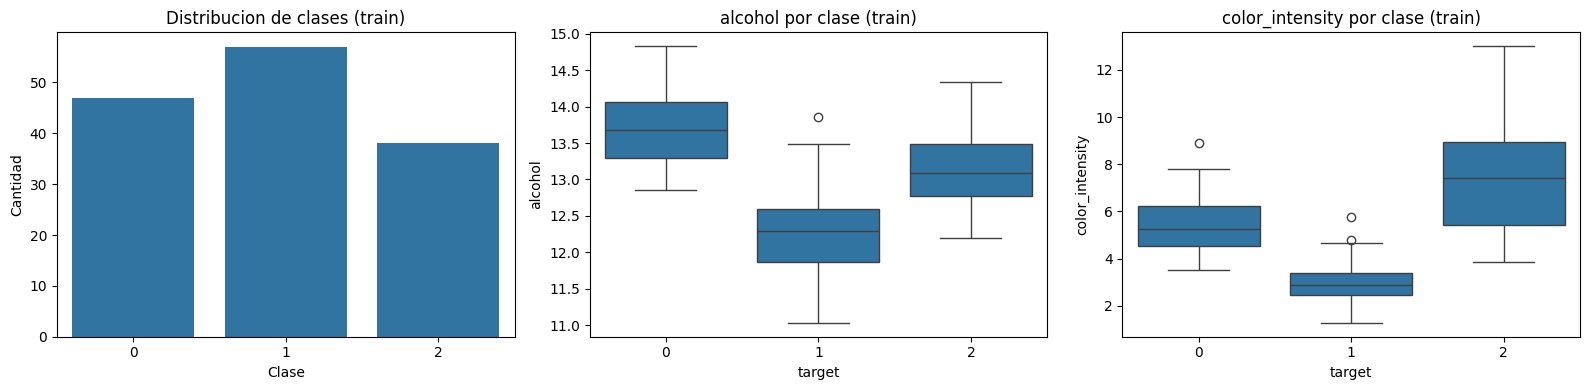

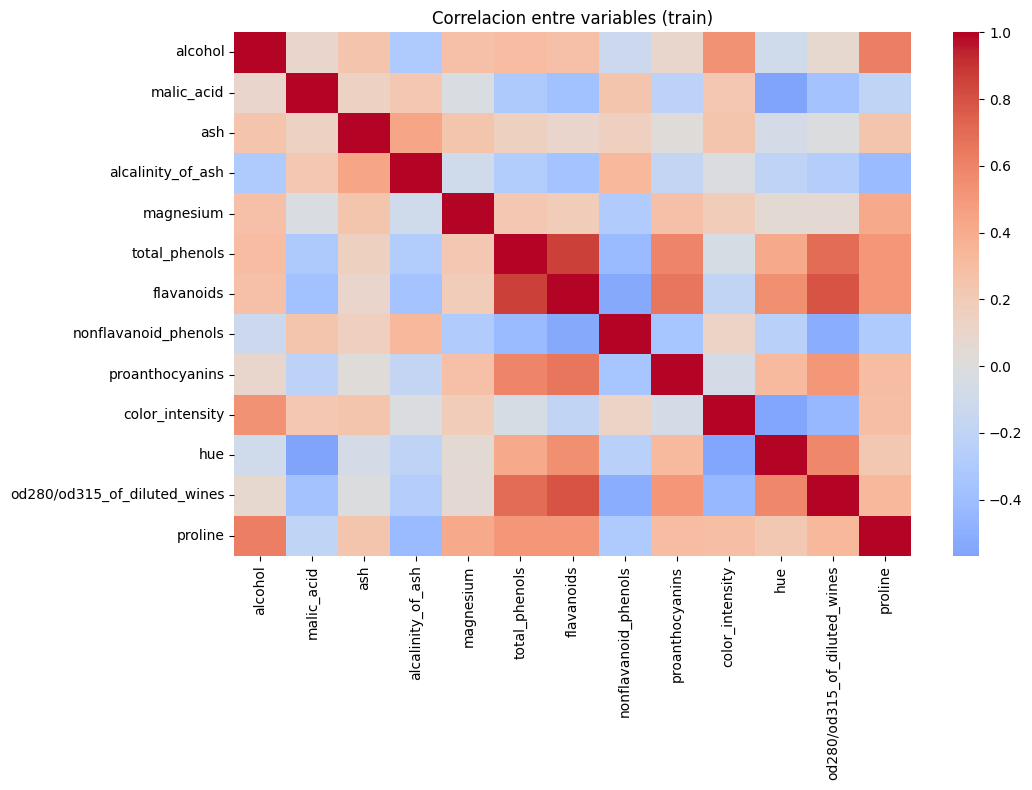

In [7]:
# Todas las visualizaciones se calculan exclusivamente con train_df.
fig, axes = plt.subplots(1, 3, figsize=(16, 4))

sns.countplot(data=train_df, x="target", ax=axes[0])
axes[0].set_title("Distribucion de clases (train)")
axes[0].set_xlabel("Clase")
axes[0].set_ylabel("Cantidad")

for ax, feature in zip(axes[1:], ["alcohol", "color_intensity"]):
    sns.boxplot(data=train_df, x="target", y=feature, ax=ax)
    ax.set_title(f"{feature} por clase (train)")

plt.tight_layout()
plt.show()

plt.figure(figsize=(11, 8))
correlation = train_df.drop(columns=["target"]).corr()
sns.heatmap(correlation, cmap="coolwarm", center=0, annot=False)
plt.title("Correlacion entre variables (train)")
plt.tight_layout()
plt.show()

**Hallazgos:**

1. En entrenamiento quedaron 47 ejemplos de la clase 0, 57 de la clase 1 y 38 de la clase 2; las tres clases siguen representadas.
2. Las medianas de `alcohol` y `color_intensity` difieren entre clases en los boxplots, así que son variables que pueden ayudar a separarlas.
3. `flavanoids` y `total_phenols` están fuertemente correlacionadas (r ≈ 0.86). Las variables también tienen escalas muy distintas (por ejemplo, `proline` llega a 1515 frente a valores de `alcohol` cercanos a 11–15), lo que debe considerarse para modelos sensibles al escalado.

## 4. Persistencia de datos y contrato

In [8]:
train_df = train_df.reset_index(drop=True)
test_df = test_df.reset_index(drop=True)

train_df.to_csv(PROCESSED_DATA_DIR / "train.csv", index=False)
test_df.to_csv(PROCESSED_DATA_DIR / "test.csv", index=False)

contract = {
    "target": "target",
    "features": [column for column in df.columns if column != "target"],
    "random_state": RANDOM_STATE,
    "test_size": 0.20,
}
(ARTIFACTS_DIR / "data_contract.json").write_text(
    json.dumps(contract, indent=2),
    encoding="utf-8",
)

347

In [9]:
# Verificación de entrega
assert (PROCESSED_DATA_DIR / "train.csv").exists()
assert (PROCESSED_DATA_DIR / "test.csv").exists()
assert (ARTIFACTS_DIR / "data_contract.json").exists()
print("Challenge 1 completado.")

Challenge 1 completado.


## Checklist

- [x] Cargué el CSV desde `data/raw`.
- [x] Revisé calidad y distribución de la clase.
- [x] Realicé un split estratificado.
- [x] No exploré el conjunto de test.
- [x] Guardé los tres artefactos requeridos.